**Run in Google Colab:** upload `coolhead_model.py` into the same folder as this notebook
(folder icon on the left → Upload), then Runtime → Run all (about 1 minute). Results appear in the
`coolhead_model_results` and `charts` folders.

In [1]:
%pip install -q pvlib
import os
if not os.path.exists("coolhead_model.py"):
    raise FileNotFoundError("coolhead_model.py not found: upload it next to this notebook "
                            "(folder icon on the left -> Upload), then run again.")


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


# CoolHead roof heat model (v2 notebook)
Estimates how hot a flat concrete roof gets, and how much heat flows into the room below,
with and without the CoolHead canopy. It runs through a hot clear-sky "design day" for
Faisalabad, repeating the day until the roof settles into a daily cycle.

The model itself lives in `coolhead_model.py`; this notebook only runs it and draws the charts.
Formulas, references and all settings are explained in `model_readme.md`.

Cases compared
1. Bare concrete roof
2. White-painted roof (the cheap alternative judges will ask about)
3. Dry white canopy (shade only)
4. CoolHead wet canopy, fabric kept wet 08:00-19:00, natural breeze only (stage 1)
5. CoolHead wet canopy, wet only 11:00-17:00 (water-saving schedule)
6. CoolHead wet canopy + backup fan (stage 2)

Model versions
- **v1** – the original notebook model.
- **v2** (default) – v1 plus the fixes from the model review: wet fabric lets more sun through,
  a wetness factor for the cloth, the roof's open sides see the surroundings instead of the sky,
  and the air in the gap under the canopy is modelled properly.

These are **modelled** results built from published physics and stated assumptions,
not measurements.

## Choose the model
Change `MODEL_VERSION` to `"v1"` to get the original notebook results. Put any setting you want to
change into `SETTINGS_OVERRIDES`, for example `{"wet_fraction": 0.8}` once the cloth-weighing
experiment has measured it. The table lists every setting the chosen version uses.

In [2]:
import numpy as np, pandas as pd
import coolhead_model as cm
from dataclasses import replace

MODEL_VERSION = cm.DEFAULT_MODEL_VERSION   # "v2"; use "v1" for the original notebook model
SETTINGS_OVERRIDES = {}                    # e.g. {"wet_fraction": 0.8}

model = cm.create_model(MODEL_VERSION, **SETTINGS_OVERRIDES)
OUT = "coolhead_model_results"
os.makedirs(OUT, exist_ok=True)
print(f"Model {model.version}: {model.description}")
settings = pd.DataFrame(cm.settings_info(MODEL_VERSION))
settings["value"] = [getattr(model.settings, n) for n in settings.name]
settings[["name", "label", "unit", "value"]]

Model v2: Improved model (fixes from initial_findings.md)


,name,label,unit,value
0,room_c,Indoor air temperature (AC set point),C,26.00
1,h_in,"Ceiling-to-room heat transfer (ASHRAE, heat fl...",W/m2K,6.10
2,slab_thick,Slab thickness,m,0.15
3,slab_k,Slab conductivity,W/mK,1.60
4,slab_rho,Slab density,kg/m3,2400.00
5,slab_c,Slab specific heat,J/kgK,880.00
6,slab_nodes,Slab layers in the calculation,,15.00
7,bare_absorptance,Bare concrete: solar absorptance,,0.70
8,bare_emissivity,Bare concrete: emissivity,,0.90
9,white_absorptance,White paint: solar absorptance,,0.30


## Weather for the design day
Climate-average temperatures for Faisalabad; dew point 10 °C for dry June, 25 °C for monsoon July.
Sunlight is the clear-sky value, so this is a worst-case sunny day.

In [3]:
pd.DataFrame({name: dict(date=sc.date, max_air_C=sc.tmax, min_air_C=sc.tmin, dewpoint_C=sc.dewpoint,
                         wind_ms=sc.wind, sun_factor=sc.sun_factor) for name, sc in cm.SCENARIOS.items()}).T

,date,max_air_C,min_air_C,dewpoint_C,wind_ms,sun_factor
"June (hot, dry)",2026-06-15,40.3,26.7,10.0,2.0,1.0
"July (hot, humid)",2026-07-20,37.3,27.3,25.0,2.0,1.0


## Run all cases for both seasons

In [4]:
results, hourly = [], {}
for sname, sc in cm.SCENARIOS.items():
    for case, label in cm.CASES.items():
        df, s = model.run(case, sc)
        s.update(season=sname, label=label); results.append(s)
        hourly[(sname, case)] = df
        out = df.iloc[::int(600 / model.settings.dt)].copy()     # one row every 10 minutes
        out["water_L_m2_h"] = out.pop("evap_kg_m2s") * 3600
        out["fan_on"] = out.fan_on.astype(int)
        out.round(2).to_csv(f"{OUT}/day_{sname.split()[0].lower()}_{case}.csv", index=False)
summary = pd.DataFrame(results)
for sname in cm.SCENARIOS:
    m = summary.season == sname
    base = summary[m & (summary.case == "bare")].heat_in_Wh_m2_day.iloc[0]
    summary.loc[m, "heat_cut_vs_bare_pct"] = 100 * (1 - summary.loc[m, "heat_in_Wh_m2_day"] / base)
cols = ["season", "label", "peak_roof_C", "mean_roof_C", "peak_ceiling_C", "heat_in_Wh_m2_day",
        "heat_cut_vs_bare_pct", "peak_heat_in_Wm2", "water_L_m2_day", "fan_hours"]
summary[cols].round(1).to_csv(f"{OUT}/summary.csv", index=False)
print(summary[cols].round(1).to_string(index=False))

           season                   label  peak_roof_C  mean_roof_C  peak_ceiling_C  heat_in_Wh_m2_day  heat_cut_vs_bare_pct  peak_heat_in_Wm2  water_L_m2_day  fan_hours
  June (hot, dry)           Bare concrete         57.0         38.5            43.5             1167.5                   0.0             106.6             0.0        0.0
  June (hot, dry)             White paint         41.2         31.5            34.5              528.9                  54.7              51.8             0.0        0.0
  June (hot, dry) Dry canopy (shade only)         39.0         32.9            33.5              645.4                  44.7              45.8             0.0        0.0
  June (hot, dry)    CoolHead wet 08-19 h         36.9         31.7            32.2              533.1                  54.3              38.0             7.8        0.0
  June (hot, dry)    CoolHead wet 11-17 h         37.1         32.2            32.4              579.1                  50.4              39.2        

## Does wind help?
Same June day, wind from calm to breezy. The bare roof is included so the **% heat cut** shows
whether the canopy's advantage grows or shrinks with wind (wind cools a bare roof too).

In [5]:
june = cm.SCENARIOS["June (hot, dry)"]
wind_rows = []
for v in [0.3, 0.5, 1.0, 2.0, 3.0, 4.0]:
    sc = replace(june, wind=v)
    bare = model.run("bare", sc)[1]["heat_in_Wh_m2_day"]
    for case in ["bare", "wet_canopy", "wet_canopy_fan"]:
        _, s = model.run(case, sc)
        s.update(wind_ms=v, heat_cut_vs_bare_pct=100 * (1 - s["heat_in_Wh_m2_day"] / bare))
        wind_rows.append(s)
wind_df = pd.DataFrame(wind_rows)
wcols = ["case", "wind_ms", "peak_roof_C", "heat_in_Wh_m2_day", "heat_cut_vs_bare_pct", "water_L_m2_day", "fan_hours"]
wind_df[wcols].round(2).to_csv(f"{OUT}/wind_test.csv", index=False)
print(wind_df[wcols].round(1).to_string(index=False))

          case  wind_ms  peak_roof_C  heat_in_Wh_m2_day  heat_cut_vs_bare_pct  water_L_m2_day  fan_hours
          bare      0.3         60.9             1351.0                   0.0             0.0        0.0
    wet_canopy      0.3         37.7              540.1                  60.0             5.1        0.0
wet_canopy_fan      0.3         37.7              540.1                  60.0             5.1        0.0
          bare      0.5         60.4             1322.8                   0.0             0.0        0.0
    wet_canopy      0.5         37.5              538.2                  59.3             5.5        0.0
wet_canopy_fan      0.5         37.5              538.2                  59.3             5.5        0.0
          bare      1.0         59.1             1261.5                   0.0             0.0        0.0
    wet_canopy      1.0         37.2              534.2                  57.7             6.3        0.0
wet_canopy_fan      1.0         37.2              534.2

## How much does humidity matter?
Same June temperatures, dew point from very dry to very humid: what does wetting add over a dry canopy?

In [6]:
hum_rows = []
for td in [0, 5, 10, 15, 20, 25]:
    sc = replace(june, dewpoint=td)
    _, dry = model.run("dry_canopy", sc); _, wet = model.run("wet_canopy", sc); _, bare = model.run("bare", sc)
    hum_rows.append(dict(dewpoint_C=td, bare=bare["heat_in_Wh_m2_day"], dry_canopy=dry["heat_in_Wh_m2_day"],
                         wet_canopy=wet["heat_in_Wh_m2_day"], water_L_m2_day=wet["water_L_m2_day"],
                         peak_roof_wet=wet["peak_roof_C"], peak_roof_dry=dry["peak_roof_C"]))
hum_df = pd.DataFrame(hum_rows)
hum_df.round(2).to_csv(f"{OUT}/humidity_test.csv", index=False)
print(hum_df.round(1).to_string(index=False))

 dewpoint_C   bare  dry_canopy  wet_canopy  water_L_m2_day  peak_roof_wet  peak_roof_dry
          0 1040.3       610.0       481.3             8.3           36.2           38.6
          5 1098.4       626.7       504.6             8.1           36.5           38.8
         10 1167.5       645.4       533.1             7.8           36.9           39.0
         15 1249.4       666.2       567.4             7.4           37.4           39.2
         20 1339.3       689.1       608.4             6.9           37.9           39.5
         25 1436.8       714.2       656.6             6.3           38.6           39.8


## v1 vs v2
The same cases with both model versions (default settings), to show how much the review fixes
change the answer.

In [7]:
rows = []
for version in cm.MODELS:
    m_ = cm.create_model(version)
    for sname, sc in cm.SCENARIOS.items():
        t = m_.run_all(sc)
        t["season"] = sname
        rows.append(t)
compare = pd.concat(rows).pivot_table(index=["season", "label"], columns="model", sort=False,
                                      values=["heat_in_Wh_m2_day", "heat_cut_vs_bare_pct", "peak_roof_C"])
compare.round(1).to_csv(f"{OUT}/v1_vs_v2.csv")
compare.round(1)

heat_in_Wh_m2_day          \
model                                                    v1      v2   
season            label                                               
June (hot, dry)   Bare concrete                      1167.5  1167.5   
                  White paint                         528.9   528.9   
                  Dry canopy (shade only)             544.4   645.4   
                  CoolHead wet 08-19 h                299.9   533.1   
                  CoolHead wet 11-17 h                391.1   579.1   
                  CoolHead wet + fan                  299.9   533.1   
July (hot, humid) Bare concrete                      1312.9  1312.9   
                  White paint                         688.4   688.4   
                  Dry canopy (shade only)             574.6   628.3   
                  CoolHead wet 08-19 h                404.6   591.8   
                  CoolHead wet 11-17 h                462.1   604.3   
                  CoolHead wet + fan                  404.6   591.8   

                                          heat_cut_vs_bare_pct        \
model                                                       v1    v2   
season            label                                                
June (hot, dry)   Bare concrete                            0.0   0.0   
                  White paint                             54.7  54.7   
                  Dry canopy (shade only)                 53.4  44.7   
                  CoolHead wet 08-19 h                    74.3  54.3   
                  CoolHead wet 11-17 h                    66.5  50.4   
                  CoolHead wet + fan                      74.3  54.3   
July (hot, humid) Bare concrete                            0.0   0.0   
                  White paint                             47.6  47.6   
                  Dry canopy (shade only)                 56.2  52.1   
                  CoolHead wet 08-19 h                    69.2  54.9   
                  CoolHead wet 11-17 h                    64.8  54.0   
                  CoolHead wet + fan                      69.2  54.9   

                                          peak_roof_C        
model                                              v1    v2  
season            label                                      
June (hot, dry)   Bare concrete                  57.0  57.0  
                  White paint                    41.2  41.2  
                  Dry canopy (shade only)        37.8  39.0  
                  CoolHead wet 08-19 h           32.5  36.9  
                  CoolHead wet 11-17 h           33.7  37.1  
                  CoolHead wet + fan             32.5  36.9  
July (hot, humid) Bare concrete                  57.7  57.7  
                  White paint                    42.3  42.3  
                  Dry canopy (shade only)        37.4  38.1  
                  CoolHead wet 08-19 h           33.5  37.4  
                  CoolHead wet 11-17 h           34.0  37.4  
                  CoolHead wet + fan             33.5  37.4

## Slide charts
Draws the four presentation charts from the result files above. Chart titles are worked out from
the results, so they stay true whichever model version or settings you use.

In [8]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import font_manager

RES, CH = OUT, "charts"
os.makedirs(CH, exist_ok=True)

# Colours follow the case, the same in every chart
COL = {"bare": "#eb6834", "white": "#eda100", "dry_canopy": "#1baf7a",
       "wet_canopy": "#2a78d6", "wet_canopy_peak": "#e87ba4", "air": "#8a8f98"}
NAME = {"bare": "Bare concrete", "white": "White paint", "dry_canopy": "Dry canopy (shade only)",
        "wet_canopy": "CoolHead, wet 08–19 h", "wet_canopy_peak": "CoolHead, wet 11–17 h"}
INK, INK2, MUTED, GRID = "#1d2127", "#4a5059", "#7a808a", "#e4e6ea"
NOTE = (f"Computer model {model.version} (not measured): 150 mm concrete roof, Faisalabad clear-sky "
        f"design day, wind {june.wind:g} m/s, room {model.settings.room_c:g} °C.")

fams = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams.update({
    "font.family": "Carlito" if "Carlito" in fams else "DejaVu Sans", "font.size": 15,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "figure.facecolor": "white",
    "axes.facecolor": "white", "legend.frameon": False, "savefig.dpi": 150,
})

def frame(fig, title, subtitle, note=NOTE):
    fig.text(0.04, 0.955, title, fontsize=26, weight="bold", color=INK, va="top")
    fig.text(0.04, 0.885, subtitle, fontsize=16, color=INK2, va="top")
    fig.text(0.04, 0.025, note, fontsize=12, color=MUTED)

def spread(values, gap):
    """Label positions near each value, pushed apart so no two are closer than gap."""
    keys = sorted(values, key=values.get)
    pos, last = {}, -np.inf
    for k in keys:
        pos[k] = max(values[k], last + gap); last = pos[k]
    shift = (max(values.values()) - max(pos.values())) / 2      # re-centre after pushing up
    return {k: p + min(shift, 0) for k, p in pos.items()}

summary = pd.read_csv(f"{RES}/summary.csv")
summary["case"] = summary.label.map({v: k for k, v in cm.CASES.items()})
june_s = summary[summary.season == "June (hot, dry)"].set_index("case")

# ---------- 1. Roof surface temperature through a June day ----------
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.07, right=0.71, top=0.78, bottom=0.13)
order = ["bare", "white", "dry_canopy", "wet_canopy_peak", "wet_canopy"]
s = model.settings
ax.axvspan(s.wet_start, s.wet_end, color="#2a78d6", alpha=0.05, lw=0)
ax.text(s.wet_start + 0.2, 21.2, f"pump keeps fabric wet {s.wet_start:02.0f}–{s.wet_end:02.0f} h", fontsize=13, color=MUTED)
air = pd.read_csv(f"{RES}/day_june_bare.csv")
ax.plot(air.hour, air.air_C, color=COL["air"], lw=2, ls=(0, (5, 4)), label="Outdoor air")
peaks, days = {}, {}
for c in order:
    d = days[c] = pd.read_csv(f"{RES}/day_june_{c}.csv")
    ax.plot(d.hour, d.roof_C, color=COL[c], lw=2.6 if c in ("bare", "wet_canopy") else 2, label=NAME[c])
    peaks[c] = d.roof_C.max()
labels = dict(peaks, air=air.air_C.max())
ypos = spread(labels, gap=1.6)
for c in order + ["air"]:
    text = "Outdoor air" if c == "air" else NAME[c]
    ax.annotate(f"{text}  {labels[c]:.0f} °C peak", xy=(24.4, ypos[c]), fontsize=14,
                color=INK2 if c == "air" else INK, va="center", annotation_clip=False)
    ax.plot([24.05, 24.3], [ypos[c]] * 2, color=COL[c], lw=2 if c == "air" else 4,
            ls=(0, (3, 2)) if c == "air" else "-", solid_capstyle="round", clip_on=False)
ax.set_xlim(0, 24); ax.set_xticks(range(0, 25, 3)); ax.set_xticklabels([f"{h:02d}:00" for h in range(0, 25, 3)])
ax.set_ylim(20, 60); ax.set_ylabel("Roof surface temperature (°C)")
ax.legend(loc="upper left", fontsize=13, ncol=2)
wet = days["wet_canopy"]
afternoon = wet.hour.between(12, 17)
below_air = (wet.roof_C[afternoon] < wet.air_C[afternoon]).all()
frame(fig, f"A wet canopy keeps the roof about {peaks['bare'] - peaks['wet_canopy']:.0f} °C cooler than bare concrete",
      "Roof surface temperature on a hot, dry June day. "
      + ("Wet CoolHead stays below the air temperature all afternoon." if below_air
         else f"White paint peaks at {peaks['white']:.0f} °C, wet CoolHead at {peaks['wet_canopy']:.0f} °C."))
fig.savefig(f"{CH}/1_roof_temperature_june.png"); plt.close(fig)

# ---------- 2. Heat into the room per day, June and July ----------
fig, axes = plt.subplots(1, 2, figsize=(16, 9), sharex=True)
fig.subplots_adjust(left=0.20, right=0.97, top=0.76, bottom=0.13, wspace=0.08)
cases = ["bare", "white", "dry_canopy", "wet_canopy_peak", "wet_canopy"]
xmax = summary.heat_in_Wh_m2_day.max() * 1.3
for ax, (season, title) in zip(axes, [("June (hot, dry)", "June – hot and dry"), ("July (hot, humid)", "July – hot and humid (monsoon)")]):
    t = summary[summary.season == season].set_index("case")
    y = range(len(cases))[::-1]
    vals = [t.loc[c, "heat_in_Wh_m2_day"] for c in cases]
    ax.barh(list(y), vals, color=[COL[c] for c in cases], height=0.62, edgecolor="white", linewidth=2)
    for yi, c, v in zip(y, cases, vals):
        cut = t.loc[c, "heat_cut_vs_bare_pct"]
        ax.text(v + xmax * 0.012, yi, f"{v:,.0f}" + ("" if c == "bare" else f"   (−{cut:.0f}%)"),
                va="center", fontsize=15, color=INK)
    ax.set_title(title, fontsize=17, color=INK, loc="left", pad=10)
    ax.grid(axis="y", visible=False)
    ax.set_yticks(list(y)); ax.set_yticklabels([NAME[c] for c in cases] if ax is axes[0] else [])
    ax.tick_params(axis="y", length=0)
    ax.set_xlim(0, xmax)
    ax.set_xlabel("Heat into the room (Wh per m² of roof per day)")
wet_cut, white_cut = june_s.loc["wet_canopy", "heat_cut_vs_bare_pct"], june_s.loc["white", "heat_cut_vs_bare_pct"]
compared = ("about the same as white paint" if abs(wet_cut - white_cut) < 5
            else "more than white paint" if wet_cut > white_cut else "less than white paint")
frame(fig, f"Wet CoolHead lets in about {5 * round(wet_cut / 5):.0f}% less heat than a bare roof",
      f"24-hour heat through the ceiling into a {model.settings.room_c:g} °C room (% = cut vs bare). In June: {compared}.")
fig.savefig(f"{CH}/2_heat_into_room.png"); plt.close(fig)

# ---------- 3. Wind test ----------
wind = pd.read_csv(f"{RES}/wind_test.csv")
w = wind[wind.case == "wet_canopy"]
fig, axes = plt.subplots(1, 2, figsize=(16, 9))
fig.subplots_adjust(left=0.07, right=0.97, top=0.74, bottom=0.17, wspace=0.22)
for ax, col, ylab, ttl, fmt in [
        (axes[0], "heat_cut_vs_bare_pct", "% less heat than a bare roof", "Heat cut compared with bare concrete", "{:.0f}%"),
        (axes[1], "water_L_m2_day", "Litres per m² per day", "Water evaporated", "{:.1f}")]:
    ax.plot(w.wind_ms, w[col], color=COL["wet_canopy"], lw=2.6, marker="o", ms=9,
            markeredgecolor="white", markeredgewidth=2)
    for x, v in zip(w.wind_ms, w[col]):
        if x in (0.3, 2.0, 4.0):
            ax.annotate(fmt.format(v), (x, v), xytext=(0, 14), textcoords="offset points",
                        ha="center", fontsize=15, color=INK)
    ax.set_title(ttl, fontsize=17, color=INK, loc="left", pad=10)
    ax.set_xlabel("Wind speed (m/s)"); ax.set_ylabel(ylab)
    ax.set_xlim(0, 4.3); ax.set_ylim(0, w[col].max() * 1.25)
fan_hours = wind[wind.case == "wet_canopy_fan"].fan_hours.sum()
fig.text(0.07, 0.065, "Stage-2 fan: " + ("its rule (calm, fabric wet, roof hotter than air) was never met in any run, so it never switched on."
         if fan_hours == 0 else f"switched on for {fan_hours:.1f} h in total across the calm runs."),
         fontsize=14, color=INK2)
cut_change = w.heat_cut_vs_bare_pct.iloc[-1] - w.heat_cut_vs_bare_pct.iloc[0]
frame(fig, "More wind uses more water" + (" and shrinks the canopy's advantage" if cut_change < -1
                                          else " and grows the canopy's advantage" if cut_change > 1
                                          else ", with little change in the heat cut"),
      "CoolHead wet canopy, June, compared with a bare roof in the same wind.",
      NOTE.replace(f"wind {june.wind:g} m/s", "wind varied from 0.3 to 4 m/s"))
fig.savefig(f"{CH}/3_wind_test.png"); plt.close(fig)

# ---------- 4. Humidity ----------
hum = pd.read_csv(f"{RES}/humidity_test.csv")
fig, ax = plt.subplots(figsize=(16, 9))
fig.subplots_adjust(left=0.08, right=0.80, top=0.78, bottom=0.13)
for c in ["bare", "dry_canopy", "wet_canopy"]:
    ax.plot(hum.dewpoint_C, hum[c], color=COL[c], lw=2.6, marker="o", ms=8, markeredgecolor="white",
            markeredgewidth=2, label=NAME[c])
    ax.annotate(NAME[c], (25, hum[c].iloc[-1]), xytext=(14, 0), textcoords="offset points",
                va="center", fontsize=15, color=INK, annotation_clip=False)
ytop = hum.bare.max() * 1.15
for td, txt in [(10, "June humidity"), (25, "July humidity")]:
    ax.axvline(td, color=MUTED, lw=1, ls=(0, (2, 3)))
    ax.text(td - 0.3, ytop * 0.96, txt, ha="right", fontsize=13, color=MUTED)
gap0 = hum.dry_canopy.iloc[0] - hum.wet_canopy.iloc[0]; gap1 = hum.dry_canopy.iloc[-1] - hum.wet_canopy.iloc[-1]
ax.annotate("", xy=(0.4, hum.wet_canopy.iloc[0]), xytext=(0.4, hum.dry_canopy.iloc[0]),
            arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.5))
ax.text(0.8, (hum.wet_canopy.iloc[0] + hum.dry_canopy.iloc[0]) / 2, f"wetting saves\n{gap0:.0f} Wh",
        fontsize=14, color=INK2, va="center")
ax.annotate("", xy=(24.6, hum.wet_canopy.iloc[-1]), xytext=(24.6, hum.dry_canopy.iloc[-1]),
            arrowprops=dict(arrowstyle="<->", color=INK2, lw=1.5))
ax.text(24.2, (hum.wet_canopy.iloc[-1] + hum.dry_canopy.iloc[-1]) / 2, f"{gap1:.0f} Wh",
        fontsize=14, color=INK2, va="center", ha="right")
ax.set_xlim(-0.5, 25.5); ax.set_ylim(0, ytop)
ax.set_xlabel("Dew point (°C)  –  higher = more humid air")
ax.set_ylabel("Heat into the room (Wh per m² per day)")
ax.legend(loc="upper left", fontsize=14, bbox_to_anchor=(0.06, 1.0))
always = (hum.wet_canopy < hum.dry_canopy).all()
frame(fig, "Humid air shrinks the benefit of wetting" + (", but does not remove it" if always else ""),
      "Same June temperatures, from very dry to very humid air. "
      + ("Wetting still beats shade alone at every humidity." if always else "At high humidity wetting no longer beats shade alone."))
fig.savefig(f"{CH}/4_humidity_effect.png"); plt.close(fig)
print("charts saved in", CH)

charts saved in charts


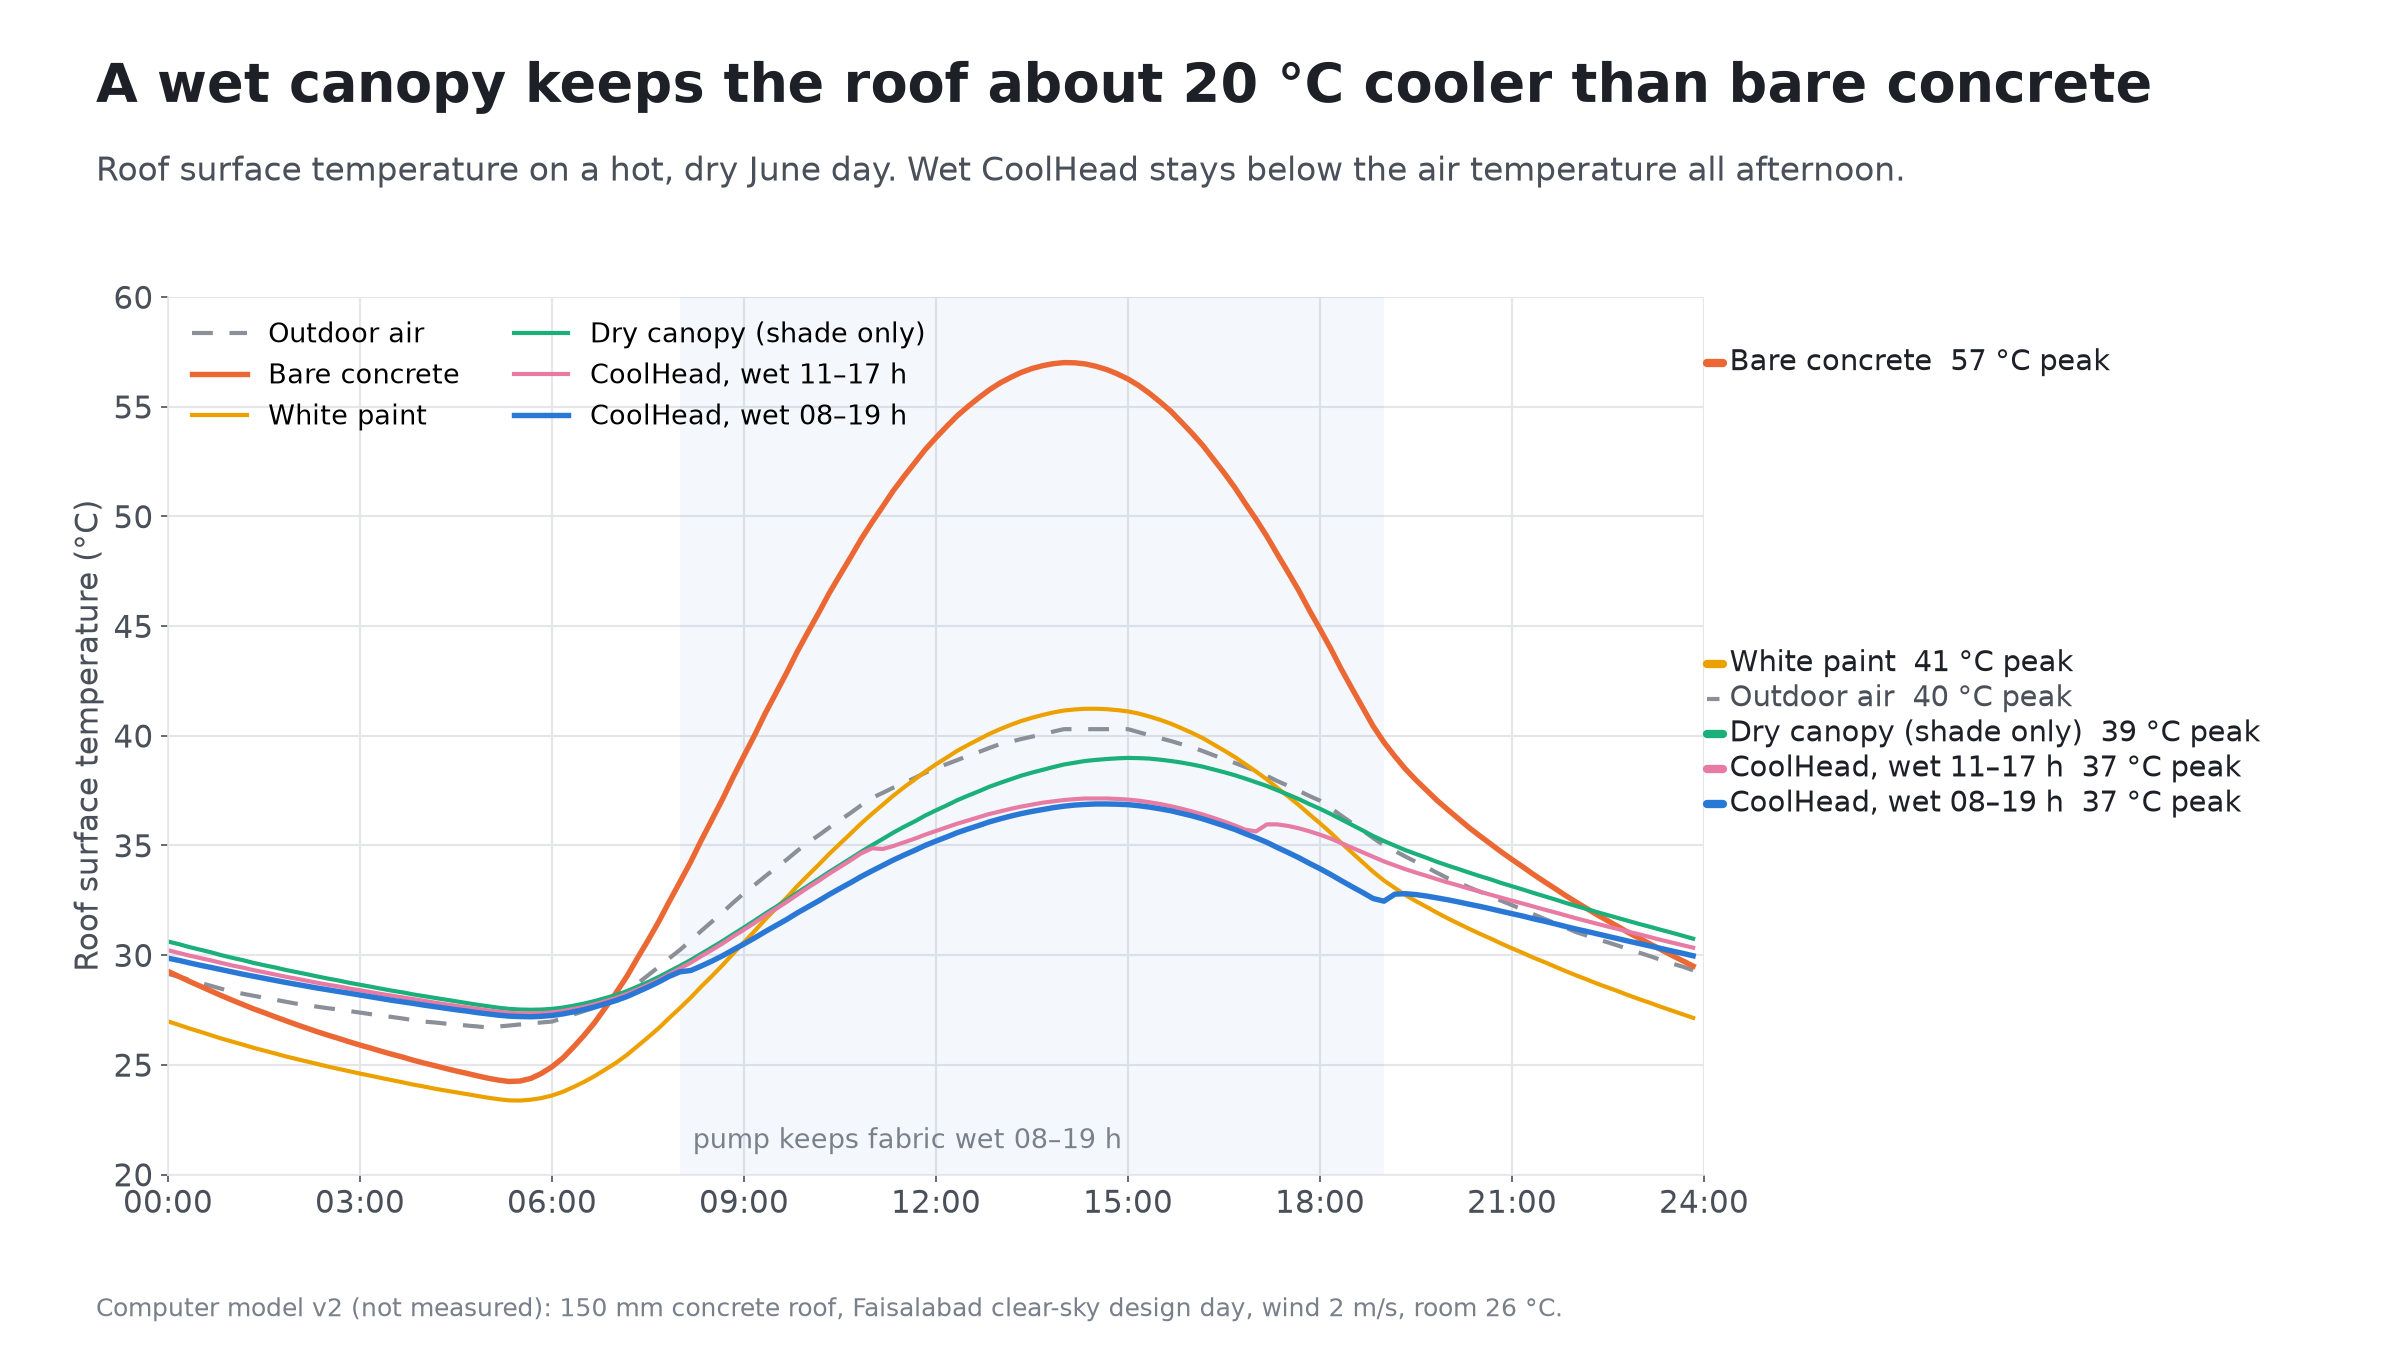

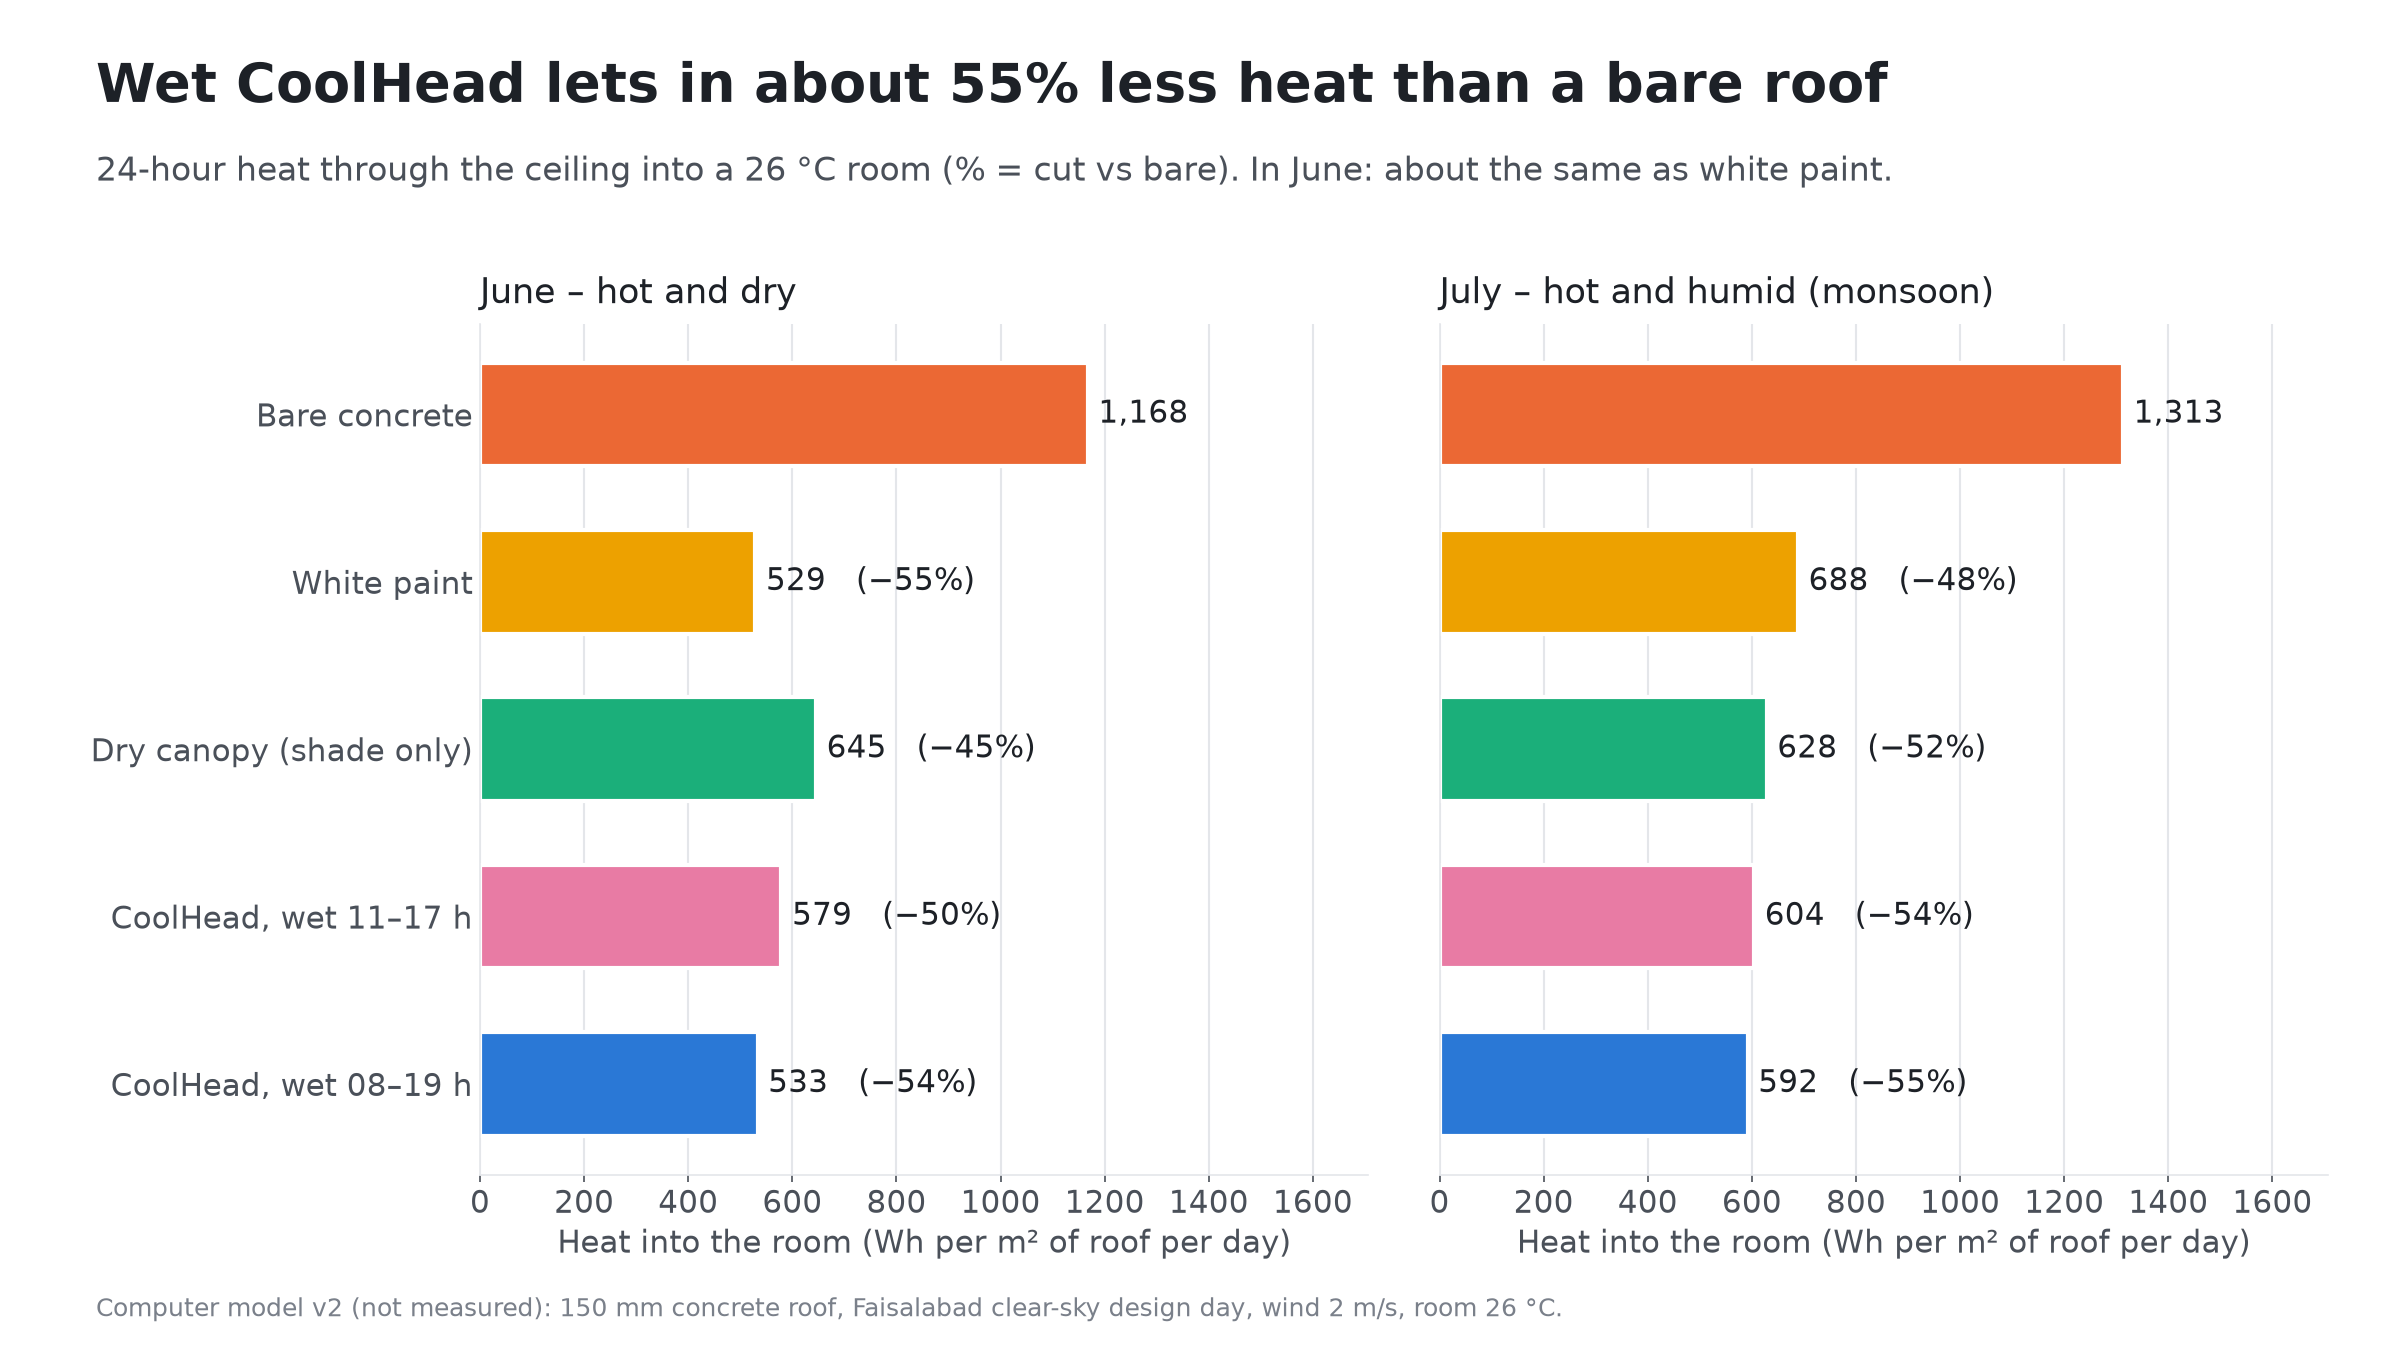

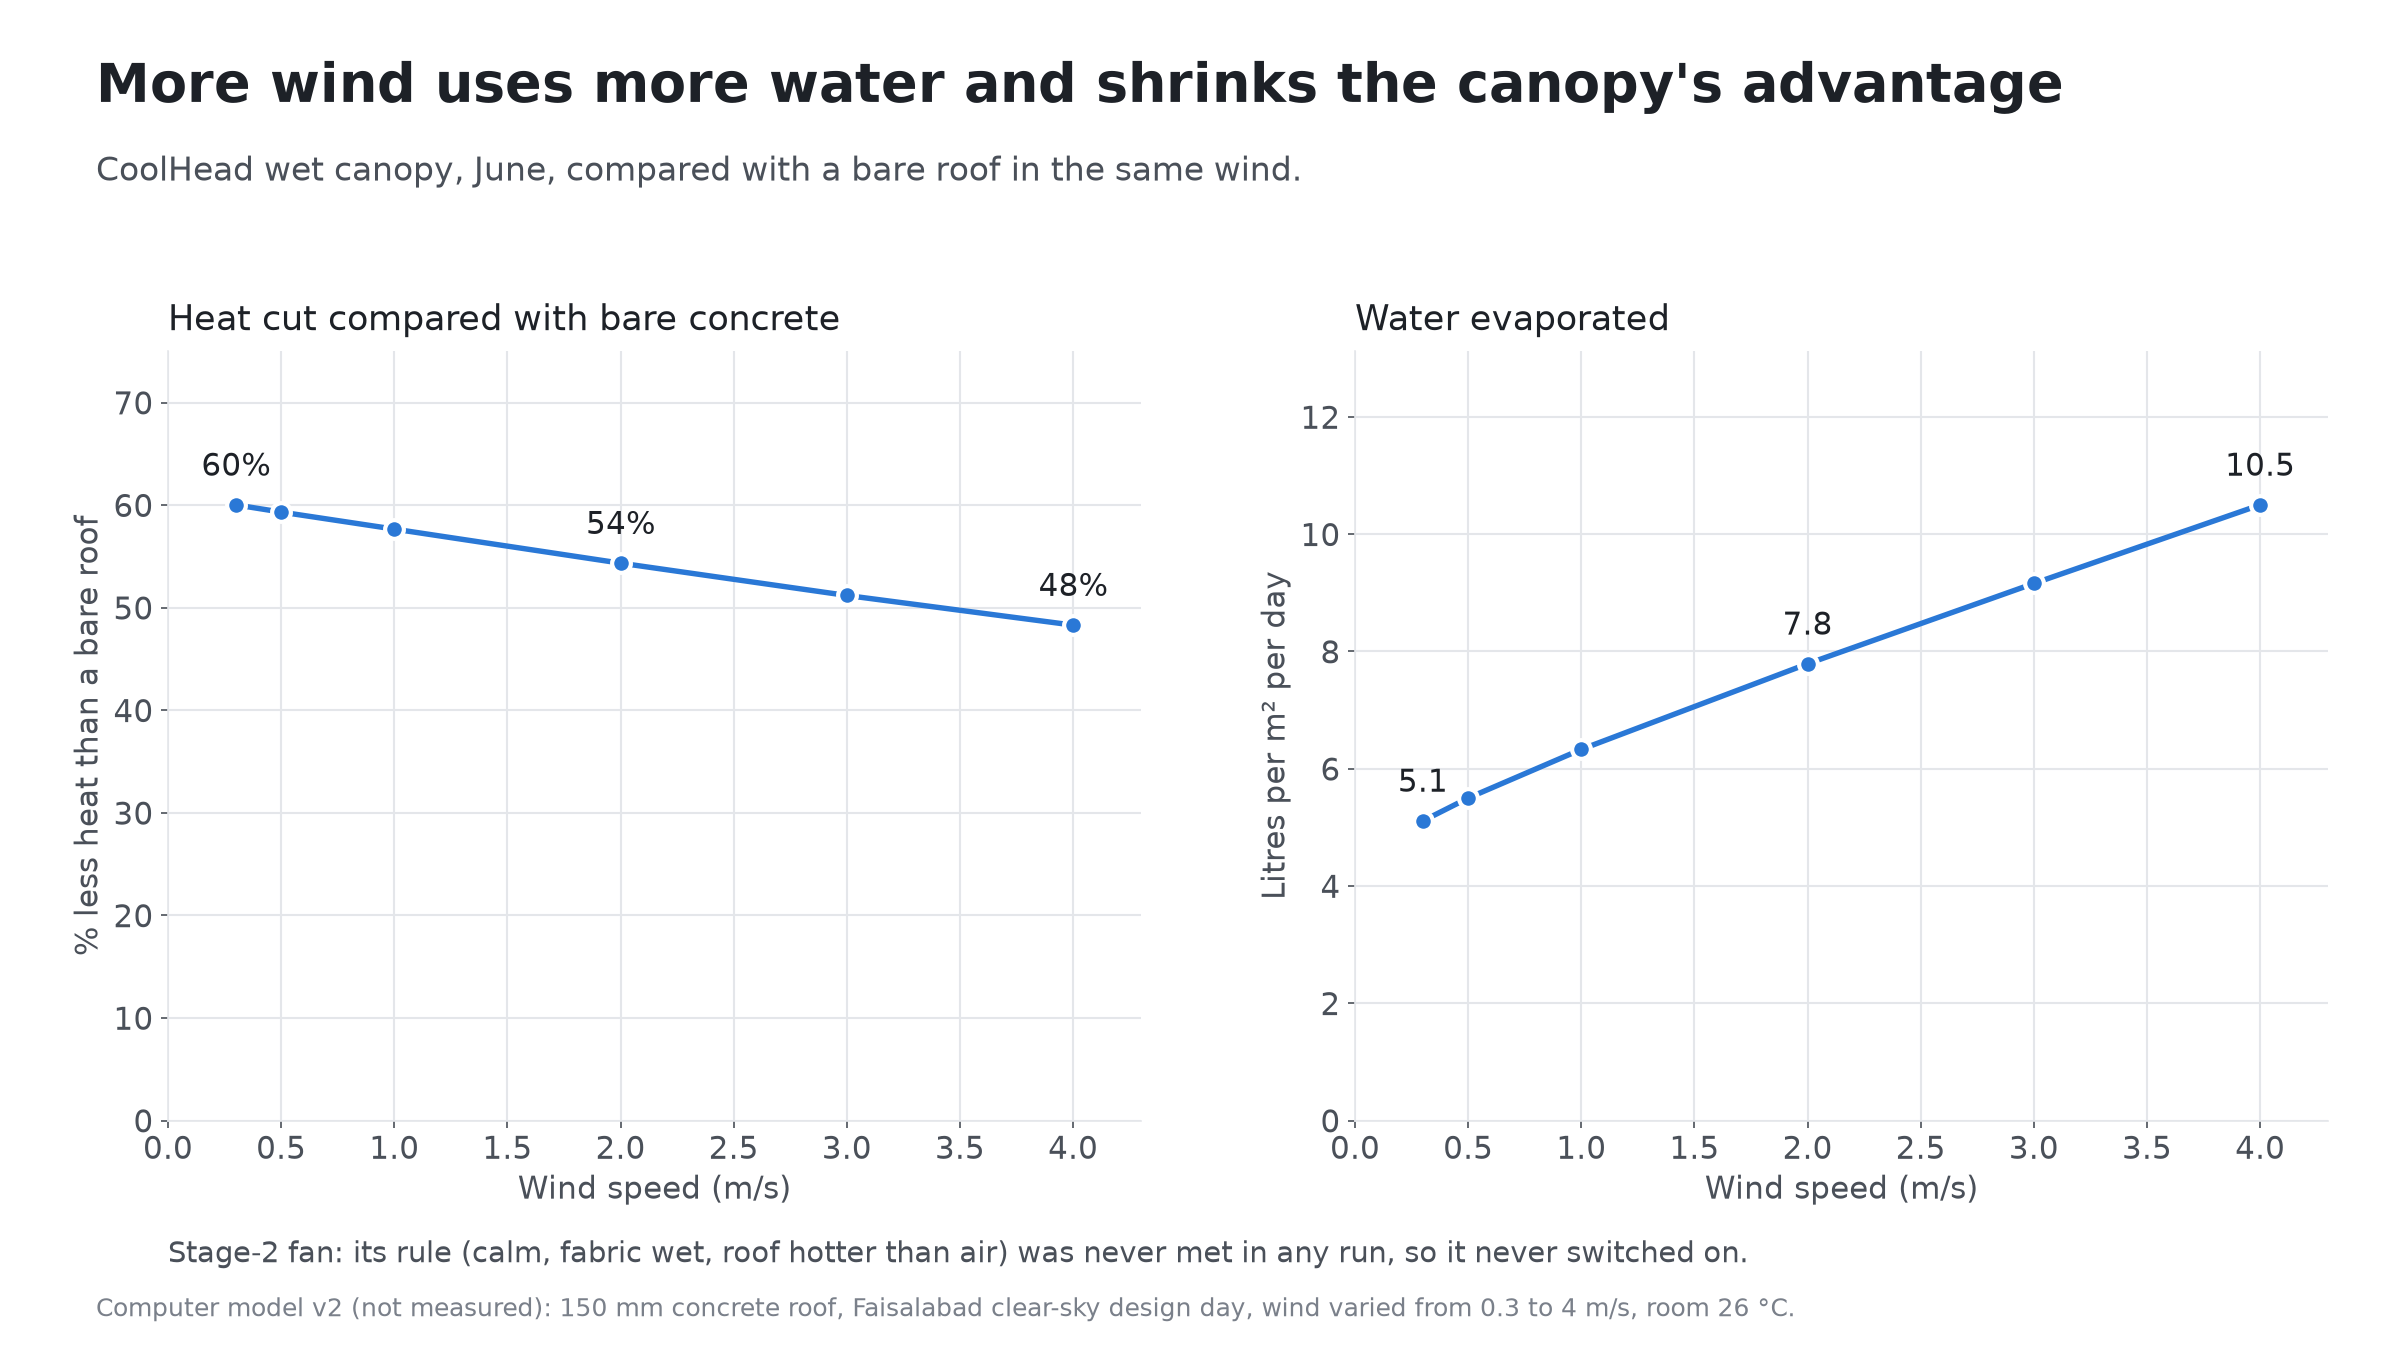

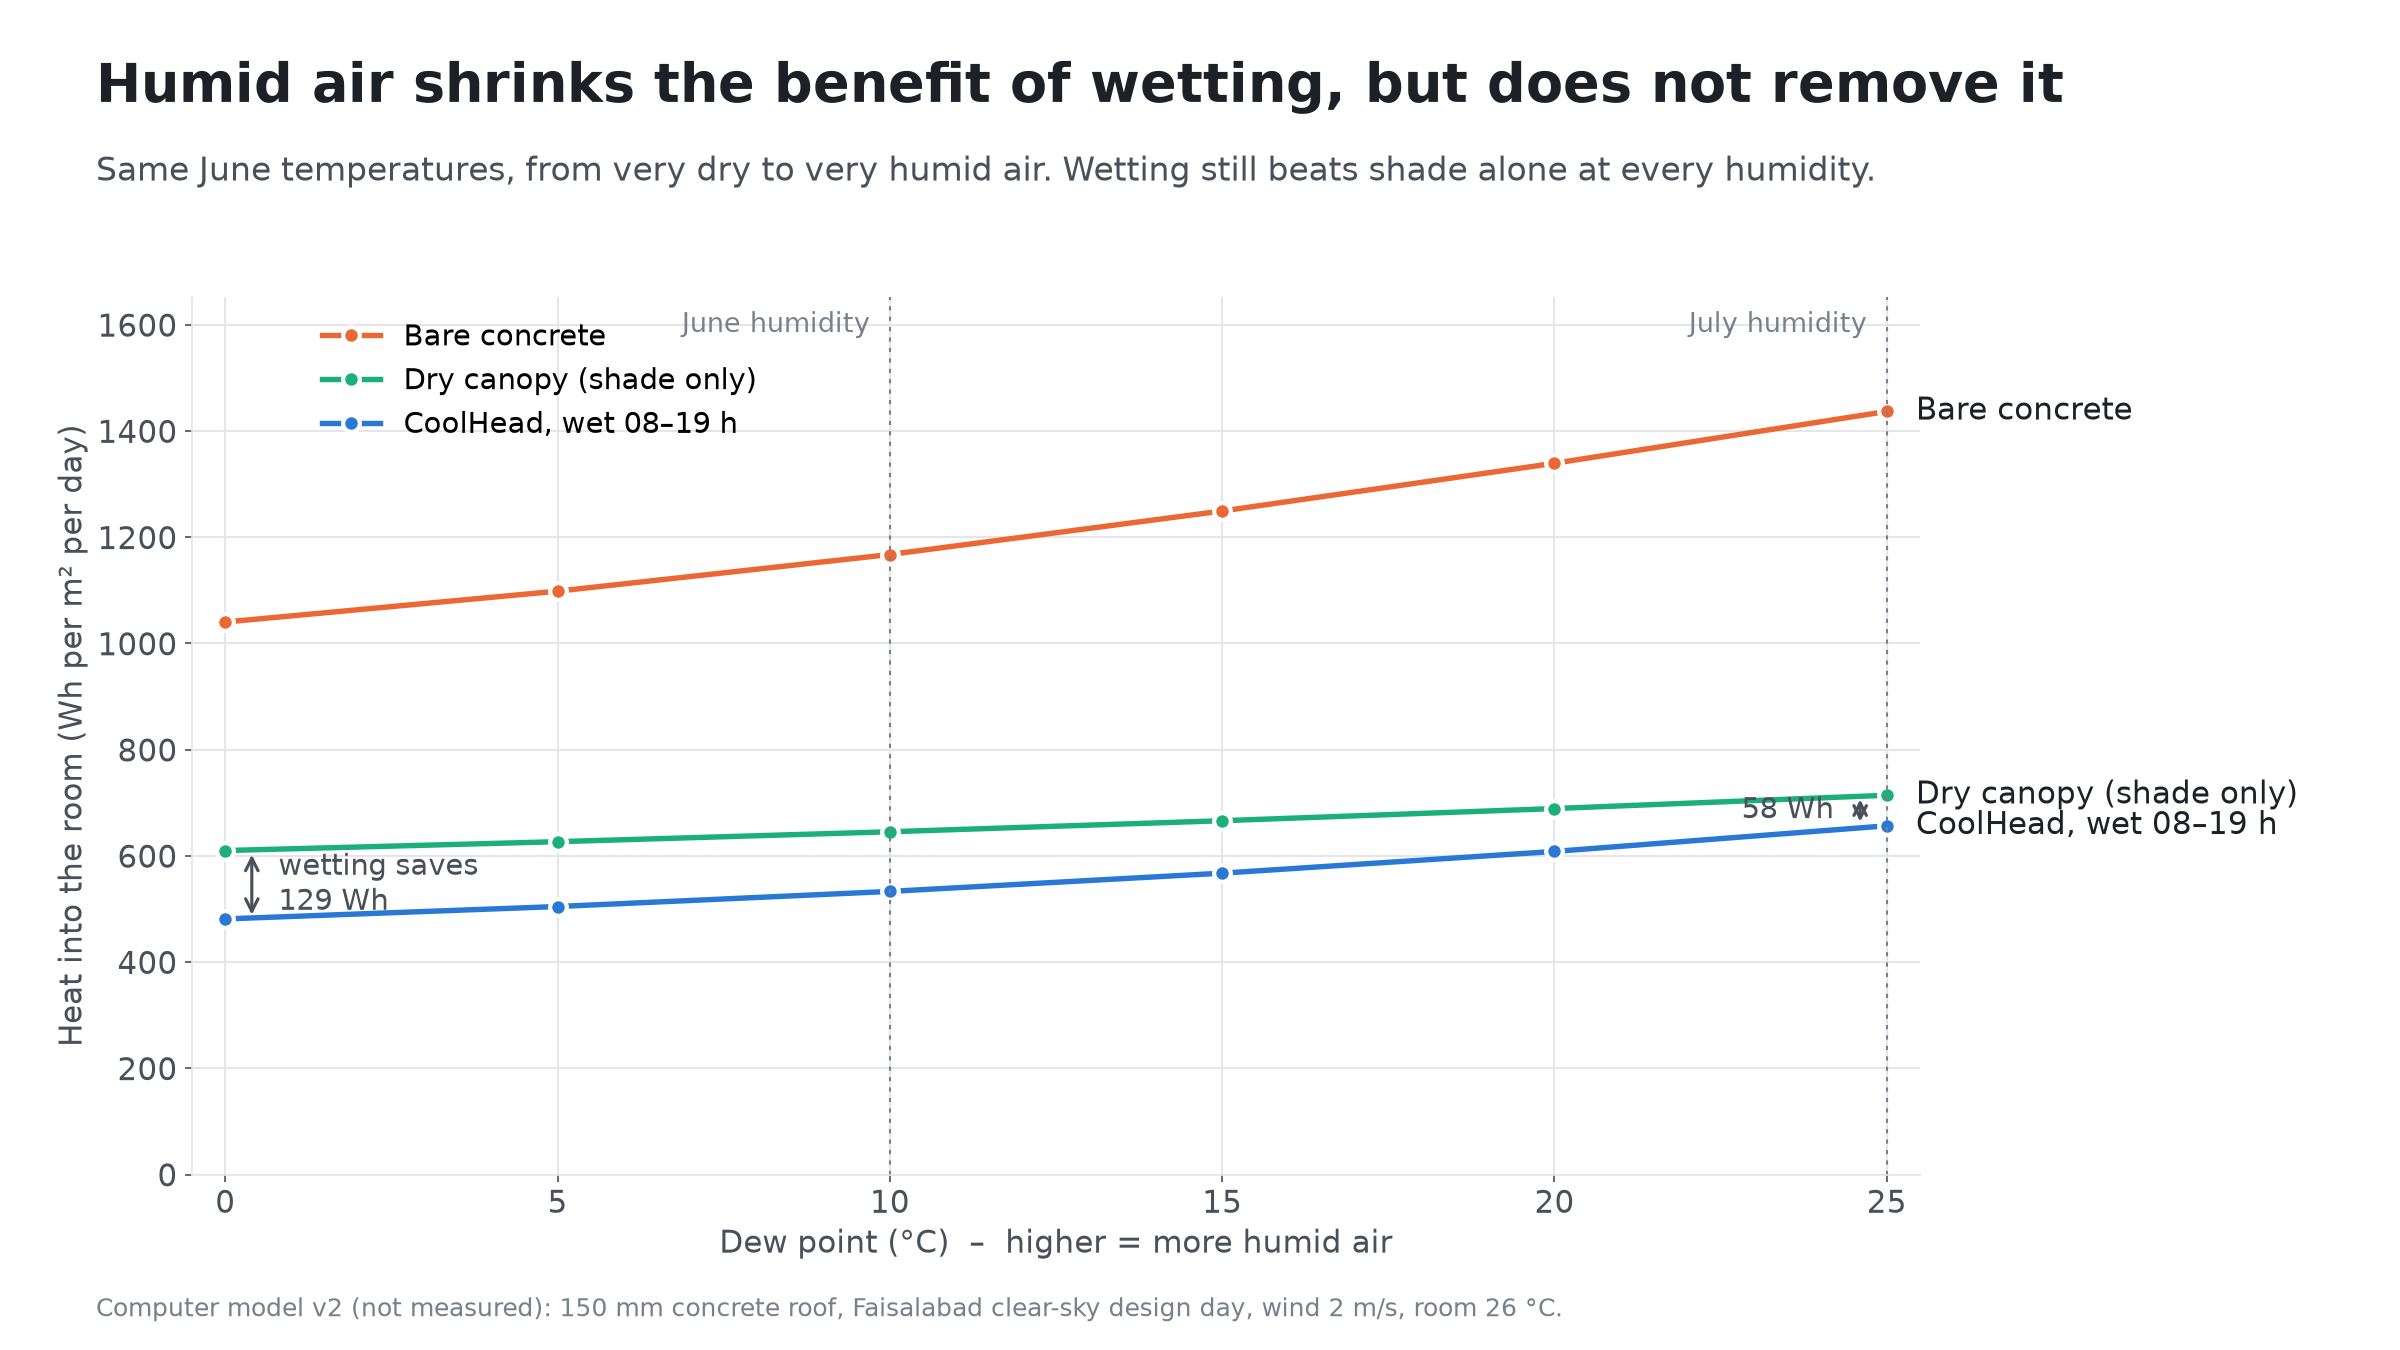

In [9]:
from IPython.display import Image, display
for f in sorted(os.listdir("charts")):
    display(Image(f"charts/{f}"))